# Bagging Exercises

![Bagging.png](Assets/Bagging.png)

# Цели обучения

- Установить связь между понятиями «бутстреппинга» и «агрегирования» (более известного как «баггинг») для снижения дисперсии
- Применять алгоритм «Случайного леса», который позволяет ещё больше снизить корреляцию, наблюдаемую в моделях, построенных методом баггинга


## Введение

Для выполнения заданий на этой неделе мы будем использовать данные об оттоке клиентов из телекоммуникационной отрасли, которые мы рассматривали на первой неделе. Файл данных называется `Orange_Telecom_Churn_Data.csv`.

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import StratifiedShuffleSplit

data_path = ['data']

## Вопрос 1

* Импортируйте данные об оттоке клиентов, содержащиеся в файле `Orange_Telecom_Churn_Data.csv`.
* Удалите все столбцы, которые, вероятно, не будут использоваться для прогнозирования.
* Осуществите соответствующее кодирование типов данных.

In [2]:
filepath = os.sep.join(data_path + ['Orange_Telecom_Churn_Data.csv'])
data = pd.read_csv(filepath)
print('Размерность:', data.shape)
print('Пропусков:', data.isna().sum().sum())
print('Дубликатов строк:', data.duplicated().sum())
data.head()

Размерность: (5000, 21)
Пропусков: 0
Дубликатов строк: 0


,state,account_length,area_code,phone_number,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [3]:
data.nunique()

state                              51
account_length                    218
area_code                           3
phone_number                     5000
intl_plan                           2
voice_mail_plan                     2
number_vmail_messages              48
total_day_minutes                1961
total_day_calls                   123
total_day_charge                 1961
total_eve_minutes                1879
total_eve_calls                   126
total_eve_charge                 1659
total_night_minutes              1853
total_night_calls                 131
total_night_charge               1028
total_intl_minutes                170
total_intl_calls                   21
total_intl_charge                 170
number_customer_service_calls      10
churned                             2
dtype: int64

В прогнозе ни в коем случае не должно фигурировать номер телефона. И вряд ли потребуются код города или штат, если только нет оснований полагать, что модель учитывает какой-то очень конкретный географический фактор.

In [4]:
data = data.drop(columns=['state', 'area_code', 'phone_number'])
data.columns.tolist()

['account_length',
 'intl_plan',
 'voice_mail_plan',
 'number_vmail_messages',
 'total_day_minutes',
 'total_day_calls',
 'total_day_charge',
 'total_eve_minutes',
 'total_eve_calls',
 'total_eve_charge',
 'total_night_minutes',
 'total_night_calls',
 'total_night_charge',
 'total_intl_minutes',
 'total_intl_calls',
 'total_intl_charge',
 'number_customer_service_calls',
 'churned']

Проанализируйте типы данных. Всё выглядит нормально, за исключением того, что `int_plan` и `voice_mail_plan` необходимо кодировать как булевы значения.

In [5]:
for column in ['intl_plan', 'voice_mail_plan']:
    data[column] = data[column].eq('yes')

data.dtypes

account_length                     int64
intl_plan                           bool
voice_mail_plan                     bool
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                             bool
dtype: object

**Вывод по вопросу 1.** В наборе 5000 записей и 21 столбец, пропусков и дубликатов нет.

- Удалили `phone_number` (у каждого клиента свой номер, 5000 уникальных значений), а также `state` (51 значение) и `area_code` (3 значения), так как географические признаки вряд ли влияют на отток.
- Столбцы `intl_plan` и `voice_mail_plan` со значениями `'yes'`/`'no'` перевели в `bool`. Целевая переменная `churned` уже имеет тип `bool`, остальные 15 признаков числовые.
- Масштабирование не нужно, так как решающие деревья не чувствительны к масштабу признаков.

## Вопрос 2

* Проанализируйте распределение прогнозируемой переменной (`churned`).
* Разделите данные на обучающую и тестовую выборки. На основании распределения решите, следует ли использовать стратифицированное деление.
* Проанализируйте распределение предикторной переменной в обучающих и тестовых данных.

In [6]:
data['churned'].value_counts().to_frame().assign(share=data['churned'].value_counts(normalize=True).round(4))

,count,share
churned,,
False,4293,0.8586
True,707,0.1414


Учитывая асимметрию переменной-предиктора, давайте разбиваем данные, стратифицировав значения *churned*.

In [7]:
feature_columns = data.columns.drop('churned')
X, y = data[feature_columns], data['churned']

splitter = StratifiedShuffleSplit(n_splits=1, test_size=1500, random_state=42)
train_idx, test_idx = next(splitter.split(X, y))
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
print('Train:', X_train.shape, 'Test:', X_test.shape)

pd.DataFrame({
    'train': y_train.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True),
}).round(4)

Train: (3500, 17) Test: (1500, 17)


,train,test
churned,,
False,0.8586,0.8587
True,0.1414,0.1413


**Вывод по вопросу 2.** Классы несбалансированы: 85.86 % клиентов остались и только 14.14 % ушли. Поэтому данные разделили со стратификацией с помощью `StratifiedShuffleSplit`: 3500 объектов в обучающей выборке и 1500 в тестовой. Доля ушедших в обеих выборках почти совпадает с исходной (14.14 % и 14.13 %), поэтому метрики для редкого класса на тесте получаются надёжнее.

## Вопрос 3

* Постройте модели «случайного леса» с различным количеством деревьев и оцените ошибку «out-of-bag» для каждой из этих моделей.
* Постройте график полученных ошибок «out-of-bag» в зависимости от количества деревьев.

*Подсказка:* поскольку изменяется только количество деревьев, можно использовать флаг `warm_start`, чтобы модель каждый раз просто добавляла новые деревья к существующей модели. Для обновления количества деревьев используйте метод `set_params`.

In [8]:
def oob_errors(model, n_trees_list, X, y):
    errors = []
    for n_trees in n_trees_list:
        model.set_params(n_estimators=n_trees)
        model.fit(X, y)
        errors.append(1 - model.oob_score_)
    return pd.Series(errors, index=pd.Index(n_trees_list, name='n_trees'))


n_trees_list = [30, 50, 100, 150, 200, 300, 400]
rf_model = RandomForestClassifier(oob_score=True, warm_start=True, random_state=42, n_jobs=-1)
rf_oob = oob_errors(rf_model, n_trees_list, X_train, y_train).rename('RandomForest')
rf_oob.round(4)

n_trees
30     0.0497
50     0.0491
100    0.0451
150    0.0451
200    0.0449
300    0.0443
400    0.0440
Name: RandomForest, dtype: float64

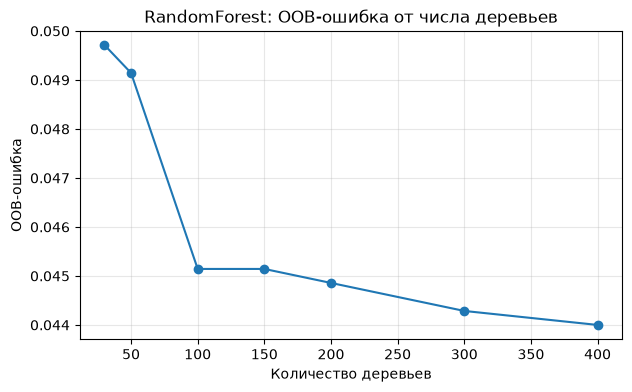

In [9]:
ax = rf_oob.plot(marker='o', figsize=(7, 4))
ax.set(xlabel='Количество деревьев', ylabel='OOB-ошибка', title='RandomForest: OOB-ошибка от числа деревьев')
ax.grid(alpha=0.3)
plt.show()

Похоже, что количество ошибок стабилизировалось на уровне 100–150 деревьев.

**Вывод по вопросу 3.** OOB-ошибка считается на объектах, которые не попали в бутстрэп-выборку дерева, поэтому её можно использовать как оценку ошибки без тестовой выборки. С ростом числа деревьев ошибка снижается с 0.0497 (30 деревьев) до 0.0451 (100 деревьев), а дальше почти не меняется (0.0440 при 400). Чем больше деревьев усредняется, тем меньше дисперсия, но после 100-150 деревьев выигрыш уже очень маленький.

Перебор начинается с 30 деревьев, потому что при очень малом числе деревьев некоторые объекты ни разу не оказываются вне бутстрэп-выборки и OOB-оценку для них посчитать нельзя.

## Вопрос 4

* Повторите задание из вопроса 3, используя дополнительные рандомизированные деревья (`ExtraTreesClassifier`). Обратите внимание, что для этой модели параметр `bootstrap` необходимо установить в значение `True`.
* Сравните ошибки метода «out-of-bag» для двух различных типов моделей.

In [10]:
et_model = ExtraTreesClassifier(oob_score=True, bootstrap=True, warm_start=True, random_state=42, n_jobs=-1)
et_oob = oob_errors(et_model, n_trees_list, X_train, y_train).rename('ExtraTrees')
et_oob.round(4)

n_trees
30     0.0694
50     0.0674
100    0.0629
150    0.0611
200    0.0626
300    0.0603
400    0.0609
Name: ExtraTrees, dtype: float64

Объедините два датафрейма в один, чтобы упростить построение графиков.

In [11]:
oob_df = pd.concat([rf_oob, et_oob], axis=1)
oob_df.round(4)

,RandomForest,ExtraTrees
n_trees,,
30,0.0497,0.0694
50,0.0491,0.0674
100,0.0451,0.0629
150,0.0451,0.0611
200,0.0449,0.0626
300,0.0443,0.0603
400,0.0440,0.0609


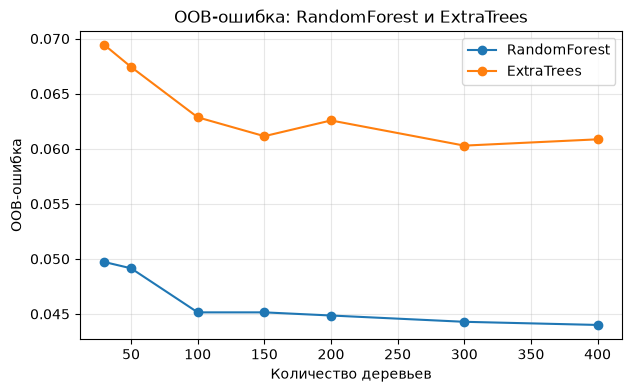

In [12]:
ax = oob_df.plot(marker='o', figsize=(7, 4))
ax.set(xlabel='Количество деревьев', ylabel='OOB-ошибка', title='OOB-ошибка: RandomForest и ExtraTrees')
ax.grid(alpha=0.3)
plt.show()

Модель «случайного леса» демонстрирует стабильно более высокую эффективность по сравнению с моделью «дополнительных рандомизированных деревьев».

**Вывод по вопросу 4.** При любом числе деревьев OOB-ошибка ExtraTrees (0.060-0.069) выше, чем у случайного леса (0.044-0.050). В ExtraTrees пороги разбиения выбираются случайно, из-за этого деревья меньше коррелируют между собой, но каждое дерево получается менее точным (растёт смещение). На этих данных рост смещения оказался сильнее, чем выигрыш от снижения дисперсии. Обе кривые выходят на плато примерно после 100-150 деревьев, небольшие колебания у ExtraTrees (в пределах ±0.002) связаны с шумом OOB-оценки.

## Вопрос 5

* Выберите одну из моделей, демонстрирующих хорошие результаты, и рассчитайте показатели ошибок и матрицу путаницы на тестовом наборе данных.
* Учитывая распределение предсказанных классов, какой показатель является наиболее важным? А какой может вводить в заблуждение?

In [13]:
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

print('Число деревьев:', rf_model.n_estimators)
print(classification_report(y_test, y_pred, digits=3))

pd.Series({
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred),
    'recall': recall_score(y_test, y_pred),
    'f1': f1_score(y_test, y_pred),
    'roc_auc': roc_auc_score(y_test, y_proba),
}).round(3)

Число деревьев: 400
              precision    recall  f1-score   support

       False      0.963     0.993     0.978      1288
        True      0.948     0.769     0.849       212

    accuracy                          0.961      1500
   macro avg      0.955     0.881     0.913      1500
weighted avg      0.961     0.961     0.960      1500



accuracy     0.961
precision    0.948
recall       0.769
f1           0.849
roc_auc      0.923
dtype: float64

In [14]:
cm = confusion_matrix(y_test, y_pred)
pd.DataFrame(cm, index=['true: False', 'true: True'], columns=['pred: False', 'pred: True'])

,pred: False,pred: True
true: False,1279,9
true: True,49,163


Неудивительно, что показатель воспроизведения для класса «Ушедшие клиенты» (True) довольно низкий, поскольку их количество весьма невелико. Тем не менее, мы показываем лучшие результаты, чем при случайном угадывании: точность составляет 0,932 (против 0,85 при случайном угадывании).

**Ответ на вопрос 5.** Для оценки взяли случайный лес из 400 деревьев, так как у него самая низкая OOB-ошибка. Результаты на тестовой выборке:

| Метрика | Значение |
|---|---|
| accuracy | 0.961 |
| precision (ушедшие) | 0.948 |
| recall (ушедшие) | 0.769 |
| F1 (ушедшие) | 0.849 |
| ROC-AUC | 0.923 |

По матрице ошибок модель нашла 163 из 212 ушедших клиентов, пропустила 49 и ошибочно отнесла к ушедшим только 9 клиентов.

- **Вводит в заблуждение accuracy.** Если всегда предсказывать, что клиент не уйдёт, accuracy уже будет 0.859 (доля класса `False` в тесте). Поэтому высокая accuracy почти ничего не говорит о том, как модель находит ушедших клиентов.
- **Самый важный показатель - recall (и F1) для класса ушедших.** Задача модели - найти клиентов, которые собираются уйти. Пропущенный клиент (FN) означает потерянный доход, а лишнее предложение об удержании (FP) обычно стоит дешевле. Recall 0.769 значит, что почти четверть уходящих клиентов модель не находит. Recall можно повысить, если снизить порог вероятности, это видно по кривой точность-полнота в вопросе 6.

## Вопрос 6

* Распечатайте или отобразите матрицу путаницы.
* Постройте кривые ROC-AUC и точность-воспроизводимость.
* Постройте график важности признаков.

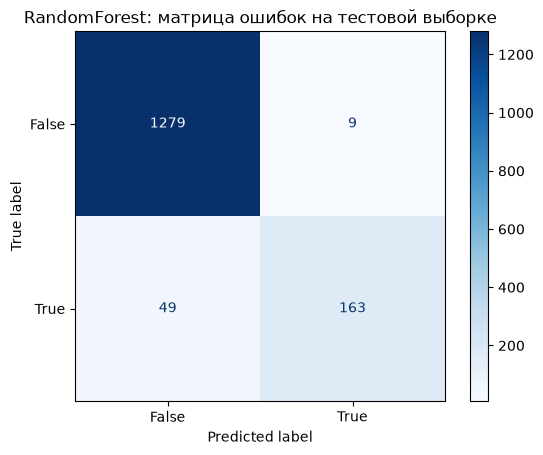

In [15]:
ConfusionMatrixDisplay(cm, display_labels=rf_model.classes_).plot(cmap='Blues')
plt.title('RandomForest: матрица ошибок на тестовой выборке')
plt.show()

Кривые ROC-AUC и «точность-охватываемость».

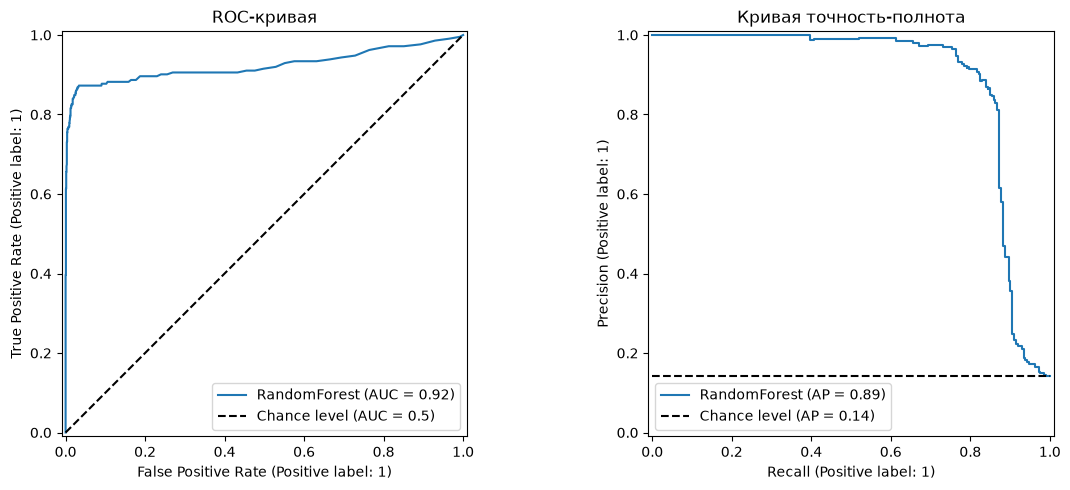

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, y_proba, name='RandomForest', ax=axes[0], plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(y_test, y_proba, name='RandomForest', ax=axes[1], plot_chance_level=True)
axes[0].set_title('ROC-кривая')
axes[1].set_title('Кривая точность-полнота')
plt.tight_layout()
plt.show()

Важность признаков. Общая ежедневная стоимость является наиболее значимым предиктором оттока клиентов.

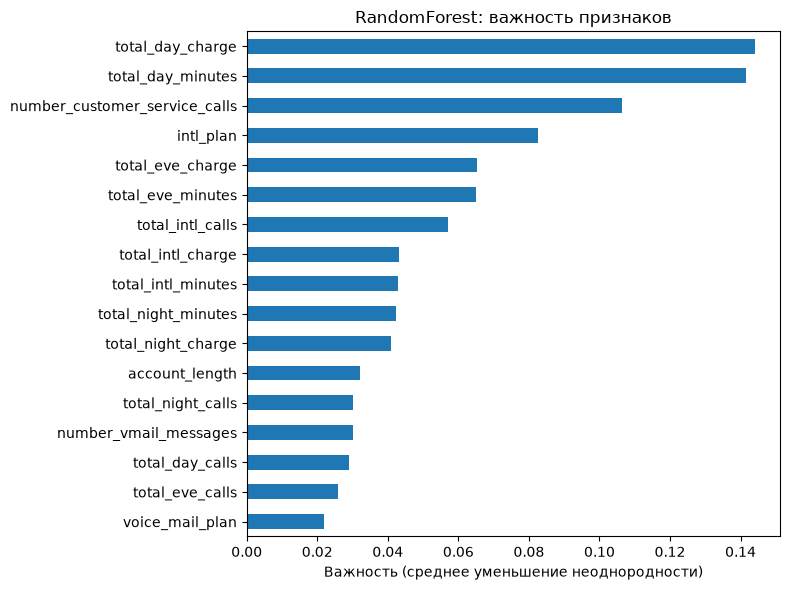

In [17]:
feature_importances = pd.Series(rf_model.feature_importances_, index=feature_columns).sort_values()
ax = feature_importances.plot.barh(figsize=(8, 6))
ax.set(xlabel='Важность (среднее уменьшение неоднородности)', title='RandomForest: важность признаков')
plt.tight_layout()
plt.show()

**Вывод по вопросу 6.**

- **ROC-кривая (AUC = 0.92).** Кривая быстро поднимается до TPR примерно 0.87 при FPR около 0.03, а дальше растёт медленно. Это значит, что примерно 13 % ушедших клиентов модель считает лояльными и даёт им низкую вероятность оттока.
- **Кривая точность-полнота.** При несбалансированных классах она информативнее, чем ROC. Средняя точность AP = 0.89 при базовом уровне 0.14. Precision держится выше 0.9 примерно до recall 0.82, а после recall около 0.87 резко падает.
- **Важность признаков.** Самые важные признаки - `total_day_charge` (0.144) и `total_day_minutes` (0.142), затем `number_customer_service_calls` (0.106) и `intl_plan` (0.083). `total_day_charge` и `total_day_minutes` коррелируют почти на 100 %, так как стоимость пропорциональна минутам, поэтому важность делится между ними. По сути это один фактор - дневное потребление с общей важностью около 0.29, то есть дневная стоимость действительно главный предиктор оттока.